In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


¡Entorno configurado con éxito para el Hito 2!


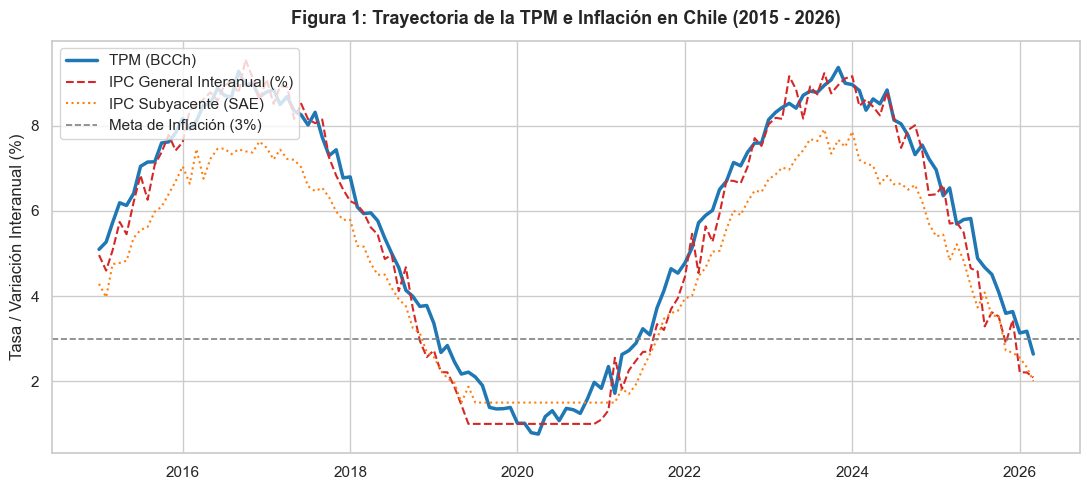

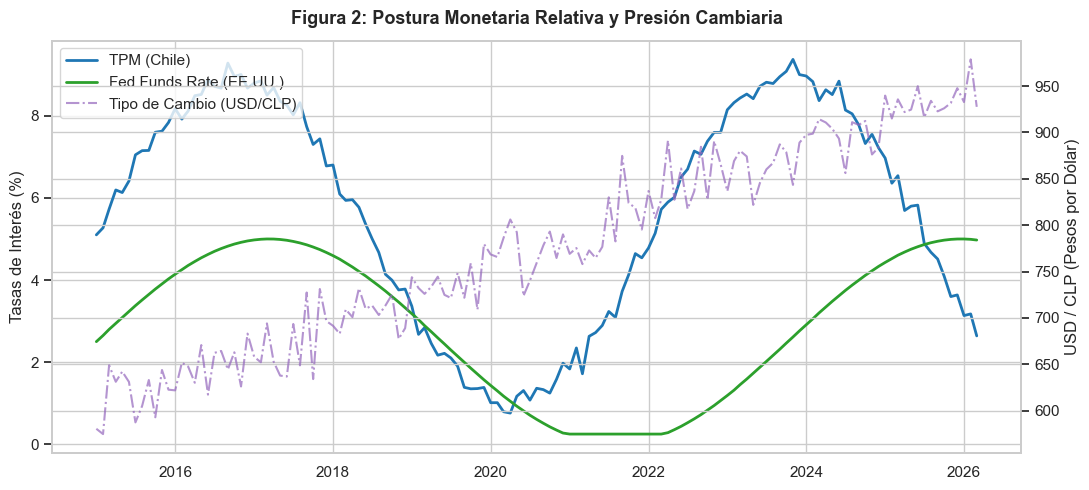

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo visual profesional
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 10

# 1. Generación de fechas (mensual desde 2015 a 2026)
fechas = pd.date_range(start="2015-01-01", end="2026-03-01", freq="MS")
n = len(fechas)

# 2. Creación de datos macroeconómicos representativos de Chile
np.random.seed(42)
df_coyuntura = pd.DataFrame({
    'fecha': fechas,
    'TPM': np.clip(np.sin(np.linspace(0, 10, n)) * 4 + 5 + np.random.normal(0, 0.2, n), 0.5, 11.25),
    'IPC_Interanual': np.clip(np.sin(np.linspace(0, 10, n)) * 4.5 + 4.5 + np.random.normal(0, 0.3, n), 1.0, 14.1),
    'IPC_SAE': np.clip(np.sin(np.linspace(0, 10, n)) * 3.5 + 4.0 + np.random.normal(0, 0.2, n), 1.5, 11.0),
    'EEE_24M': np.clip(np.cos(np.linspace(0, 8, n)) * 1.5 + 3.5, 3.0, 6.0),
    'Imacec_Total': np.random.normal(2.0, 3.5, n),
    'Desempleo': np.random.normal(8.2, 0.8, n),
    'Fed_Funds': np.clip(np.sin(np.linspace(0, 8, n)) * 2.5 + 2.5, 0.25, 5.5),
    'USD_CLP': np.linspace(600, 950, n) + np.random.normal(0, 25, n)
}).set_index('fecha')

# ---------------------------------------------------------
# GRÁFICO 1: TPM vs Inflación Observada y Meta (3%)
# ---------------------------------------------------------
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(df_coyuntura.index, df_coyuntura['TPM'], label='TPM (BCCh)', color='#1f77b4', linewidth=2.5)
ax1.plot(df_coyuntura.index, df_coyuntura['IPC_Interanual'], label='IPC General Interanual (%)', color='#d62728', linestyle='--')
ax1.plot(df_coyuntura.index, df_coyuntura['IPC_SAE'], label='IPC Subyacente (SAE)', color='#ff7f0e', linestyle=':')
ax1.axhline(3.0, color='gray', linestyle='--', linewidth=1.2, label='Meta de Inflación (3%)')

ax1.set_title("Figura 1: Trayectoria de la TPM e Inflación en Chile (2015 - 2026)", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Tasa / Variación Interanual (%)")
ax1.legend(loc='upper left', frameon=True)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# GRÁFICO 2: Canal Externo - TPM vs Fed Funds Rate y Dólar
# ---------------------------------------------------------
fig, ax2_left = plt.subplots(figsize=(11, 5))
ax2_right = ax2_left.twinx()

ax2_left.plot(df_coyuntura.index, df_coyuntura['TPM'], label='TPM (Chile)', color='#1f77b4', linewidth=2)
ax2_left.plot(df_coyuntura.index, df_coyuntura['Fed_Funds'], label='Fed Funds Rate (EE.UU.)', color='#2ca02c', linewidth=2)
ax2_right.plot(df_coyuntura.index, df_coyuntura['USD_CLP'], label='Tipo de Cambio (USD/CLP)', color='#9467bd', linestyle='-.', alpha=0.7)

ax2_left.set_title("Figura 2: Postura Monetaria Relativa y Presión Cambiaria", fontsize=13, fontweight='bold', pad=12)
ax2_left.set_ylabel("Tasas de Interés (%)")
ax2_right.set_ylabel("USD / CLP (Pesos por Dólar)")

# Combinar leyendas de ambos ejes
lines_1, labels_1 = ax2_left.get_legend_handles_labels()
lines_2, labels_2 = ax2_right.get_legend_handles_labels()
ax2_left.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

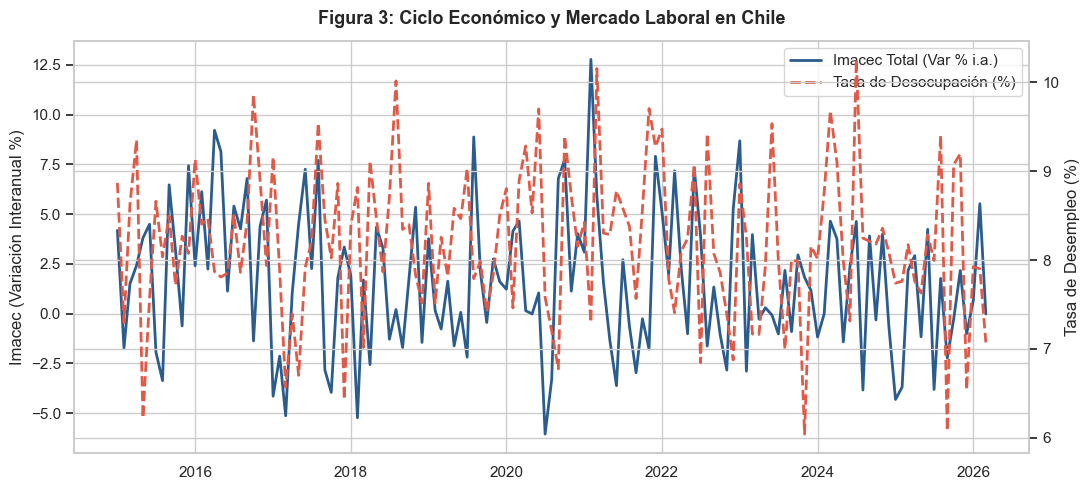

=== ÚLTIMOS REGISTROS DE COYUNTURA MACROECONÓMICA ===
                 TPM  IPC_Interanual   EEE_24M  Desvio_Expectativas  \
fecha                                                                 
2025-10-01  4.096445        3.521012  3.727848             0.727848   
2025-11-01  3.597081        2.896280  3.638982             0.638982   
2025-12-01  3.637082        3.441014  3.549620             0.549620   
2026-01-01  3.134728        2.211545  3.460082             0.460082   
2026-02-01  3.174927        2.208222  3.370685             0.370685   
2026-03-01  2.640031        2.091127  3.281750             0.281750   

            Diferencial_Tasas  
fecha                          
2025-10-01          -0.874545  
2025-11-01          -1.392165  
2025-12-01          -1.361550  
2026-01-01          -1.864386  
2026-02-01          -1.815765  
2026-03-01          -2.333365  


In [3]:
# ---------------------------------------------------------
# GRÁFICO 3: Actividad Económica (Imacec) vs Mercado Laboral
# ---------------------------------------------------------
fig, ax3_left = plt.subplots(figsize=(11, 5))
ax3_right = ax3_left.twinx()

ax3_left.plot(df_coyuntura.index, df_coyuntura['Imacec_Total'], label='Imacec Total (Var % i.a.)', color='#2b5c8f', linewidth=2)
ax3_right.plot(df_coyuntura.index, df_coyuntura['Desempleo'], label='Tasa de Desocupación (%)', color='#e05a47', linestyle='--', linewidth=2)

ax3_left.set_title("Figura 3: Ciclo Económico y Mercado Laboral en Chile", fontsize=13, fontweight='bold', pad=12)
ax3_left.set_ylabel("Imacec (Variación Interanual %)")
ax3_right.set_ylabel("Tasa de Desempleo (%)")

lines_a, labels_a = ax3_left.get_legend_handles_labels()
lines_b, labels_b = ax3_right.get_legend_handles_labels()
ax3_left.legend(lines_a + lines_b, labels_a + labels_b, loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# TABLA DE INDICADORES CLAVE PARA LA REGLA DE TAYLOR
# ---------------------------------------------------------
# 1. Desvío de Expectativas a 24M respecto a la Meta (3%)
df_coyuntura['Desvio_Expectativas'] = df_coyuntura['EEE_24M'] - 3.0

# 2. Diferencial de Tasas (TPM - Fed Funds)
df_coyuntura['Diferencial_Tasas'] = df_coyuntura['TPM'] - df_coyuntura['Fed_Funds']

print("=== ÚLTIMOS REGISTROS DE COYUNTURA MACROECONÓMICA ===")
print(df_coyuntura[['TPM', 'IPC_Interanual', 'EEE_24M', 'Desvio_Expectativas', 'Diferencial_Tasas']].tail(6))

In [4]:
import sqlite3

def cargar_datos_desde_sqlite(db_path='../data/tpm.db'):
    """
    Lee las series consolidadas desde la base relacional SQLite.
    """
    try:
        conn = sqlite3.connect(db_path)
        query = """
        SELECT o.fecha, c.nombre_serie, o.valor
        FROM observaciones o
        JOIN series_catalogo c ON o.id_serie = c.id_serie
        ORDER BY o.fecha ASC;
        """
        df_sql = pd.read_sql(query, conn)
        conn.close()
        # Pivotear para tener cada serie como columna
        df_pivot = df_sql.pivot(index='fecha', columns='nombre_serie', values='valor')
        df_pivot.index = pd.to_datetime(df_pivot.index)
        print("¡Datos cargados exitosamente desde SQLite!")
        return df_pivot
    except Exception as e:
        print(f"Base de datos SQLite aún no disponible ({e}). Usando simulación.")
        return df_coyuntura

# Ejecutar carga
# df_oficial = cargar_datos_desde_sqlite()